# Week 7 — Anatomy of a Physics Engine
### Complete, runnable reference code

**Physics 311: Mechanics — Modeling, Computing, Publishing**

---

This notebook is the executable companion to the Week 7 lesson. It uses the `lab07_engine` Python package, plus the validation runs that prove it reproduces Labs 1–6.

Run it top to bottom (**Kernel &rarr; Restart & Run All**).

---

## The one idea

Six labs, one repeated skeleton: *set up state &rarr; loop over time &rarr; compute forces &rarr; integrate &rarr; record &rarr; plot.*

An **engine** writes it once and lets you plug in what changes.

| What changed between labs | Component that owns it |
|---|---|
| The objects (mass, radius, position, orientation) | `Body` |
| The interactions (gravity, springs, drag, contact) | `Force` objects in a registry |
| The update rule (Euler, Euler-Cromer, Verlet) | `Integrator` |
| Time stepping and bookkeeping | `World` |

The test of success: **a new simulation should be a new `main`, not a new engine.**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ellipk
from scipy.signal import argrelmin
import time

from lab07_engine import (
    Body, World,
    Force, Gravity, Drag, Spring, NewtonGravity, PivotGravityTorque, Wind,
    Euler, EulerCromer, VelocityVerlet,
    resolve_pair, CircleCollisions, BoxWalls
)

plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
UT_ORANGE = '#ff8200'

print("NumPy", np.__version__)
print("Engine loaded successfully!")

NumPy 2.5.1
Engine loaded successfully!


---
## 1 &nbsp; `Body` — what the world is made of

A body owns **state** (position, velocity, orientation, spin) and **parameters** (mass, radius, moment of inertia). It owns no physics.

In [2]:
b = Body(m=2.0, r=(1, 2), v=(3, -1), radius=0.5, I=0.25, omega=4.0, name="test")
print(b)
print(f"  KE        = {b.ke():.4f} J")
print(f"  p         = {b.p()}")
print(f"  L (origin)= {b.L_about():.4f}")
print(f"  inv_m     = {b.inv_m:.4f}")

wall = Body(m=1.0, fixed=True, name="wall")
print(f"\n  fixed body inv_m = {wall.inv_m}  <- immovable by arithmetic")

Body(test, m=2.0, r=[1. 2.], v=[ 3. -1.])
  KE        = 12.0000 J
  p         = [ 6. -2.]
  L (origin)= -13.0000
  inv_m     = 0.5000

  fixed body inv_m = 0.0  <- immovable by arithmetic


---
## 2 &nbsp; `Force` — the registry and polymorphism

Every force exposes the same interface (`apply` and `potential_energy`).

In [3]:
print("Forces loaded from package:", [c.__name__ for c in
      (Gravity, Drag, Spring, NewtonGravity, PivotGravityTorque, Wind)])

Forces loaded from package: ['Gravity', 'Drag', 'Spring', 'NewtonGravity', 'PivotGravityTorque', 'Wind']


---
## 3 &nbsp; `Integrator` — swap the method, not the simulation

All three integrators share one signature: `step(world, dt)`.

In [4]:
print("Integrators:", [c.name for c in (Euler, EulerCromer, VelocityVerlet)])

Integrators: ['Euler', 'Euler-Cromer', 'Velocity Verlet']


---
## 4 &nbsp; Constraints — collisions as a separate stage

In [5]:
print("Constraints loaded: CircleCollisions, BoxWalls")

Constraints loaded: CircleCollisions, BoxWalls


---
## 5 &nbsp; `World` — the five-stage loop

In [6]:
w_test = World()
print("World initialized from package.")

World initialized from package.


---
# 6 &nbsp; Validation: reproduce Labs 1–6

Testing that the engine package reproduces expected physical behavior.

## 6.1 &nbsp; Labs 1–2: projectile

PROJECTILE  v0 = 25 m/s at 45 deg, Velocity Verlet, dt = 1e-3
  E0                = 312.5000000000 J
  max|dE|/E0        = 1.528e-14
  range (simulated) = 63.7105 m
  range (theory)    = 63.7105 m


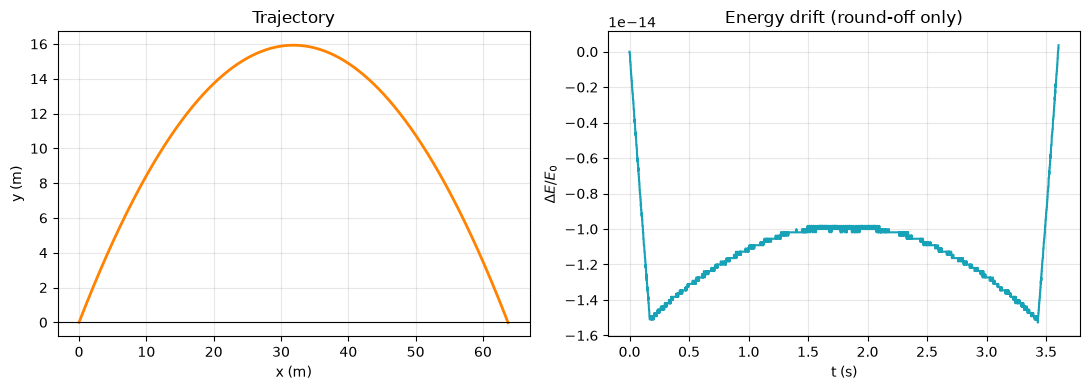

In [7]:
v0, angle = 25.0, 45.0
th = np.radians(angle)

w = World(integrator=VelocityVerlet())
w.add(Body(m=1.0, r=(0, 0), v=(v0*np.cos(th), v0*np.sin(th)), name="ball"))
w.add_force(Gravity(9.81))

w.record('t', lambda W: W.t)
w.record('x', lambda W: W.bodies[0].r[0])
w.record('y', lambda W: W.bodies[0].r[1])
w.record('E', lambda W: W.total_energy())

h = w.run(dt=0.001, t_end=3.606)
x, y, E = h['x'], h['y'], h['E']

i    = np.where(y < 0)[0][0]
frac = y[i-1] / (y[i-1] - y[i])
R    = x[i-1] + frac * (x[i] - x[i-1])

print("PROJECTILE  v0 = 25 m/s at 45 deg, Velocity Verlet, dt = 1e-3")
print(f"  E0                = {E[0]:.10f} J")
print(f"  max|dE|/E0        = {np.max(np.abs(E-E[0]))/abs(E[0]):.3e}")
print(f"  range (simulated) = {R:.4f} m")
print(f"  range (theory)    = {v0**2*np.sin(2*th)/9.81:.4f} m")

fig, ax = plt.subplots(1, 2)
ax[0].plot(x[:i+1], y[:i+1], color=UT_ORANGE, lw=2)
ax[0].axhline(0, color='k', lw=0.8); ax[0].set_xlabel('x (m)')
ax[0].set_ylabel('y (m)'); ax[0].set_title('Trajectory')
ax[1].plot(h['t'][:i+1], (E[:i+1]-E[0])/E[0], color='#17a2b8')
ax[1].set_xlabel('t (s)'); ax[1].set_ylabel(r'$\Delta E/E_0$')
ax[1].set_title('Energy drift (round-off only)')
plt.tight_layout(); plt.show()

## 6.2 &nbsp; Lab 3: the integrator showdown

SHO  k = m = 1, x0 = 1, 10 periods, dt = 0.05
integrator            max|dE|/E0     final x
Euler                 2.2071e+01      4.8004
Euler-Cromer          2.5641e-02      0.9991
Velocity Verlet       6.2500e-04      0.9997


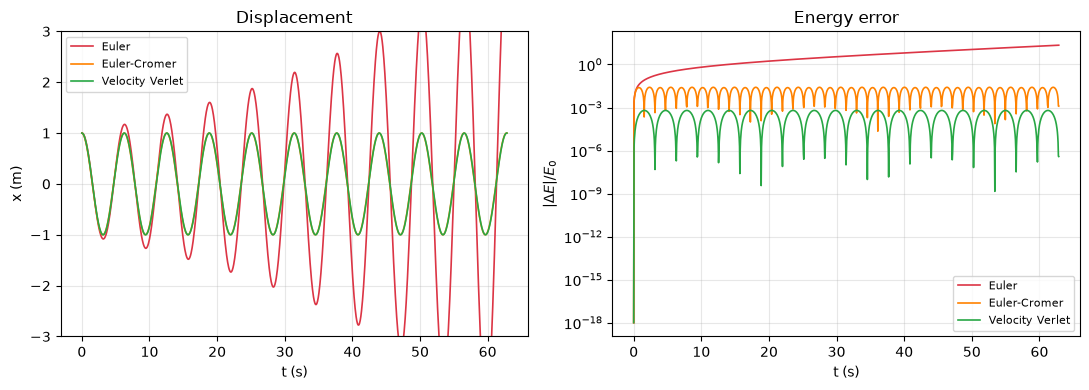

In [8]:
T_sho = 2*np.pi
rows = []

for Int in (Euler, EulerCromer, VelocityVerlet):
    w = World(integrator=Int())
    w.add(Body(m=1.0, r=(0, 0), fixed=True))
    w.add(Body(m=1.0, r=(1, 0), v=(0, 0)))
    w.add_force(Spring(0, 1, k=1.0, L0=0.0))
    w.record('t', lambda W: W.t)
    w.record('x', lambda W: W.bodies[1].r[0])
    w.record('E', lambda W: W.total_energy())
    h = w.run(dt=0.05, t_end=10*T_sho)
    rows.append((Int.name, h))

print("SHO  k = m = 1, x0 = 1, 10 periods, dt = 0.05")
print(f"{'integrator':<18}{'max|dE|/E0':>14}{'final x':>12}")
for name, h in rows:
    E = h['E']
    print(f"{name:<18}{np.max(np.abs(E-E[0]))/abs(E[0]):>14.4e}{h['x'][-1]:>12.4f}")

fig, ax = plt.subplots(1, 2)
for (name, h), c in zip(rows, ['#dc3545', UT_ORANGE, '#28a745']):
    ax[0].plot(h['t'], h['x'], label=name, lw=1.2, color=c)
    ax[1].semilogy(h['t'], np.abs(h['E']-h['E'][0])/h['E'][0] + 1e-18,
                   label=name, lw=1.2, color=c)
ax[0].set_xlabel('t (s)'); ax[0].set_ylabel('x (m)'); ax[0].set_title('Displacement')
ax[0].set_ylim(-3, 3); ax[0].legend(fontsize=8)
ax[1].set_xlabel('t (s)'); ax[1].set_ylabel(r'$|\Delta E|/E_0$')
ax[1].set_title('Energy error'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6.3 &nbsp; Lab 5: orbits and Kepler's third law

ORBIT  G = M = 1, r0 = (1,0), v0 = (0,0.8), dt = 1e-3, t = 20
integrator           max|dE/E0|   max|dL/L0|    r_min    r_max
Euler                 1.263e-01    5.476e-02   0.4752   1.1416
Euler-Cromer          9.763e-04    8.470e-15   0.4706   1.0000
Velocity Verlet       2.132e-06    5.956e-15   0.4706   1.0000


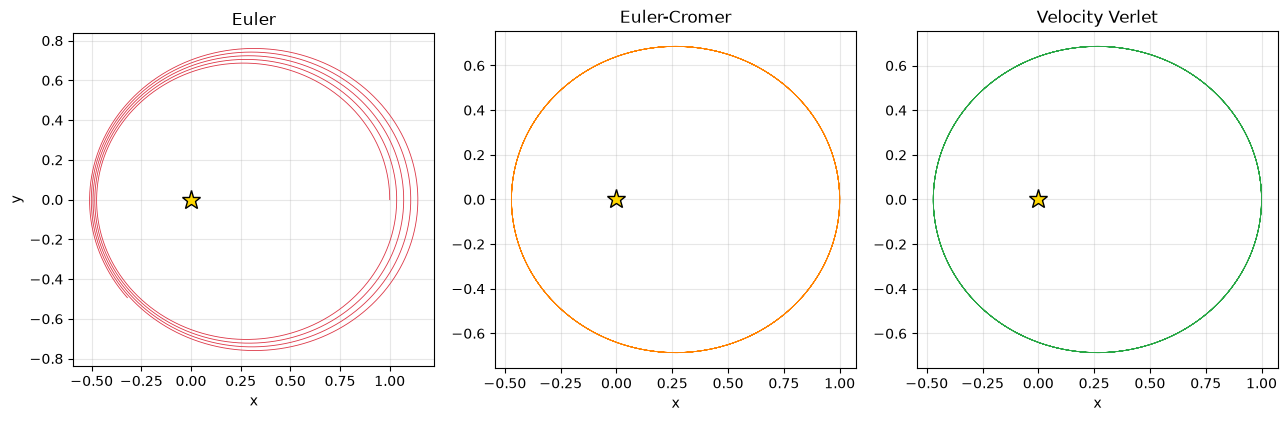

In [9]:
print("ORBIT  G = M = 1, r0 = (1,0), v0 = (0,0.8), dt = 1e-3, t = 20")
print(f"{'integrator':<18}{'max|dE/E0|':>13}{'max|dL/L0|':>13}{'r_min':>9}{'r_max':>9}")

trajs = []
for Int in (Euler, EulerCromer, VelocityVerlet):
    w = World(integrator=Int())
    w.add(Body(m=1.0,  r=(0, 0), fixed=True, name="star"))
    w.add(Body(m=1e-6, r=(1, 0), v=(0, 0.8), name="planet"))
    w.add_force(NewtonGravity(G=1.0))
    w.record('x', lambda W: W.bodies[1].r[0])
    w.record('y', lambda W: W.bodies[1].r[1])
    w.record('r', lambda W: np.linalg.norm(W.bodies[1].r))
    w.record('E', lambda W: W.total_energy())
    w.record('L', lambda W: W.angular_momentum())
    h = w.run(dt=0.001, t_end=20.0)
    E, L, r = h['E'], h['L'], h['r']
    print(f"{Int.name:<18}{np.max(np.abs(E-E[0]))/abs(E[0]):>13.3e}"
          f"{np.max(np.abs(L-L[0]))/abs(L[0]):>13.3e}{r.min():>9.4f}{r.max():>9.4f}")
    trajs.append((Int.name, h))

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, (name, h), c in zip(ax, trajs, ['#dc3545', UT_ORANGE, '#28a745']):
    a.plot(h['x'], h['y'], lw=0.6, color=c)
    a.plot(0, 0, '*', ms=14, color='gold', mec='k')
    a.set_aspect('equal'); a.set_title(name); a.set_xlabel('x')
ax[0].set_ylabel('y')
plt.tight_layout(); plt.show()

In [10]:
# Kepler's third law, measured
w = World(integrator=VelocityVerlet())
w.add(Body(m=1.0,  r=(0, 0), fixed=True))
w.add(Body(m=1e-6, r=(1, 0), v=(0, 0.8)))
w.add_force(NewtonGravity(G=1.0))
w.record('t', lambda W: W.t)
w.record('r', lambda W: np.linalg.norm(W.bodies[1].r))
h = w.run(dt=0.0005, t_end=20.0)
r, t = h['r'], h['t']

a_meas = (r.min() + r.max()) / 2
E_sp   = 0.5*0.8**2 - 1.0            # specific orbital energy
a_th   = -1 / (2*E_sp)
idx    = argrelmin(r, order=50)[0]
T_meas = np.mean(np.diff(t[idx]))

print("KEPLER CHECK  (Velocity Verlet, dt = 5e-4)")
print(f"  perihelion            = {r.min():.6f}")
print(f"  aphelion              = {r.max():.6f}")
print(f"  a  (measured)         = {a_meas:.6f}")
print(f"  a  (theory, -1/2E)    = {a_th:.6f}")
print(f"  T  (measured)         = {T_meas:.6f}")
print(f"  T  (Kepler 2*pi*a^3/2)= {2*np.pi*a_th**1.5:.6f}")

KEPLER CHECK  (Velocity Verlet, dt = 5e-4)
  perihelion            = 0.470588
  aphelion              = 1.000000
  a  (measured)         = 0.735294
  a  (theory, -1/2E)    = 0.735294
  T  (measured)         = 3.961500
  T  (Kepler 2*pi*a^3/2)= 3.961608


## 6.4 &nbsp; Lab 4: collisions

In [11]:
def collision_scene(e, walls=True):
    coll = CircleCollisions(e=e)
    cons = [coll]
    wl   = BoxWalls(0, 10, 0, 10, e=1.0) if walls else None
    if wl: cons.append(wl)
    w = World(integrator=EulerCromer(), constraints=cons)
    for p, v in zip([(2,2), (8,2), (2,8), (8,8)],
                    [(3,2), (-2,3), (2.5,-1.5), (-3,-2)]):
        w.add(Body(m=1.0, r=p, v=v, radius=0.5))
    return w, coll, wl

print("ISOLATED (walls off), t = 6 s -- momentum must hold")
print(f"{'e':>5}{'|dp|/|p0|':>14}{'KE retained':>14}{'pair hits':>11}")
for e in (1.0, 0.9, 0.5, 0.0):
    w, coll, _ = collision_scene(e, walls=False)
    p0, KE0 = w.momentum().copy(), w.kinetic_energy()
    w.run(dt=0.002, t_end=6.0)
    dp = np.linalg.norm(w.momentum()-p0) / np.linalg.norm(p0)
    print(f"{e:>5.1f}{dp:>14.3e}{100*w.kinetic_energy()/KE0:>13.2f}%{coll.count:>11d}")

print("\nIN A BOX (walls on), t = 20 s -- walls are EXTERNAL")
print(f"{'e':>5}{'KE retained':>14}{'pair hits':>11}{'wall hits':>11}")
for e in (1.0, 0.9, 0.5, 0.0):
    w, coll, wl = collision_scene(e)
    KE0 = w.kinetic_energy()
    w.run(dt=0.002, t_end=20.0)
    print(f"{e:>5.1f}{100*w.kinetic_energy()/KE0:>13.3f}%{coll.count:>11d}{wl.count:>11d}")

ISOLATED (walls off), t = 6 s -- momentum must hold
    e     |dp|/|p0|   KE retained  pair hits
  1.0     0.000e+00       100.00%          4
  0.9     2.809e-16        83.79%          4
  0.5     1.404e-16        48.03%          3
  0.0     2.809e-16        55.65%          3

IN A BOX (walls on), t = 20 s -- walls are EXTERNAL
    e   KE retained  pair hits  wall hits
  1.0      100.000%         10         37
  0.9       63.800%         10         31
  0.5       11.837%          8         18
  0.0       12.795%         11         20


## 6.5 &nbsp; Lab 6: the physical pendulum

In [12]:
m_rod, L_rod, g = 1.0, 1.0, 9.81
I_rod = m_rod * L_rod**2 / 3
d_cm  = L_rod / 2
Omega = np.sqrt(m_rod * g * d_cm / I_rod)

print(f"Rod about one end:  Omega = sqrt(3g/2L) = {Omega:.6f} rad/s")
print(f"                    T0    = {2*np.pi/Omega:.6f} s\n")
print(f"{'theta0':>8}{'T (engine)':>13}{'T (exact)':>13}{'rel err':>11}{'T/T0':>8}")

for th0 in (0.1, 0.3, 1.0, 2.0, 3.0):
    w = World(integrator=EulerCromer())
    w.add(Body(m=m_rod, r=(0, 0), I=I_rod, theta=th0, omega=0.0, name="rod"))
    w.add_force(PivotGravityTorque(0, m_rod, g, d_cm))
    w.record('t',  lambda W: W.t)
    w.record('th', lambda W: W.bodies[0].theta)
    h = w.run(dt=1e-4, t_end=12.0)

    th, t = h['th'], h['t']
    s     = np.sign(th)
    cross = np.where((s[:-1] > 0) & (s[1:] <= 0))[0]
    tc    = [t[i] + th[i]/(th[i]-th[i+1])*(t[i+1]-t[i]) for i in cross]
    T_sim = np.mean(np.diff(tc))
    T_ex  = 4/Omega * ellipk(np.sin(th0/2)**2)

    print(f"{th0:>8.1f}{T_sim:>13.6f}{T_ex:>13.6f}"
          f"{abs(T_sim-T_ex)/T_ex:>11.2e}{T_sim/(2*np.pi/Omega):>8.4f}")

Rod about one end:  Omega = sqrt(3g/2L) = 3.836014 rad/s
                    T0    = 1.637947 s

  theta0   T (engine)    T (exact)    rel err    T/T0
     0.1     1.638971     1.638971   6.10e-09  1.0006
     0.3     1.647208     1.647208   5.86e-09  1.0057
     1.0     1.746599     1.746599   3.31e-09  1.0663
     2.0     2.176675     2.176675   2.55e-09  1.3289
     3.0     4.211544     4.211544   6.07e-09  2.5712


---
# 7 &nbsp; The payoff: figure-eight three-body orbit

FIGURE-EIGHT THREE-BODY ORBIT   4 periods, Verlet, dt = 1e-4
  E0                   = -1.287141992
  max|dE/E0|           = 5.892e-09
  max|p|  (exact 0)    = 3.482e-14
  max|dL| (exact 0)    = 3.354e-14
  |r_A(4T) - r_A(0)|   = 2.788e-05


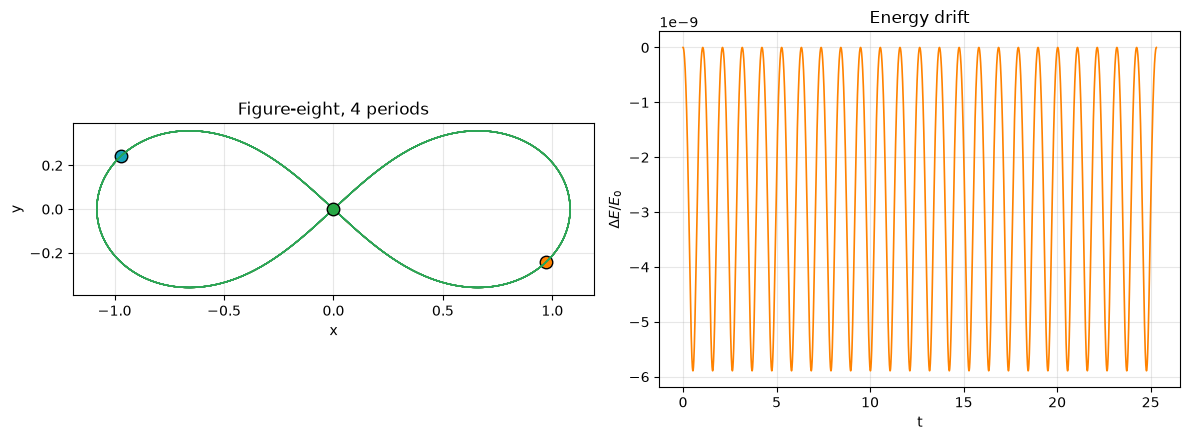

In [13]:
x1, y1   = 0.97000436, -0.24308753
vx3, vy3 = -0.93240737, -0.86473146
T_fig    = 6.32591398

w = World(integrator=VelocityVerlet())
w.add(Body(m=1, r=( x1,  y1), v=(-vx3/2, -vy3/2), name="A"))
w.add(Body(m=1, r=(-x1, -y1), v=(-vx3/2, -vy3/2), name="B"))
w.add(Body(m=1, r=(  0,   0), v=( vx3,    vy3  ), name="C"))
w.add_force(NewtonGravity(G=1.0))

for i in range(3):
    w.record(f'x{i}', lambda W, i=i: W.bodies[i].r[0])
    w.record(f'y{i}', lambda W, i=i: W.bodies[i].r[1])
w.record('t', lambda W: W.t)
w.record('E', lambda W: W.total_energy())
w.record('p', lambda W: np.linalg.norm(W.momentum()))
w.record('L', lambda W: W.angular_momentum())

h = w.run(dt=1e-4, t_end=4*T_fig, capture_every=10)
E, p, L = h['E'], h['p'], h['L']

print("FIGURE-EIGHT THREE-BODY ORBIT   4 periods, Verlet, dt = 1e-4")
print(f"  E0                   = {E[0]:.9f}")
print(f"  max|dE/E0|           = {np.max(np.abs(E-E[0]))/abs(E[0]):.3e}")
print(f"  max|p|  (exact 0)    = {p.max():.3e}")
print(f"  max|dL| (exact 0)    = {np.max(np.abs(L-L[0])):.3e}")
print(f"  |r_A(4T) - r_A(0)|   = {np.linalg.norm(w.bodies[0].r-np.array([x1,y1])):.3e}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for i, c in enumerate([UT_ORANGE, '#17a2b8', '#28a745']):
    ax[0].plot(h[f'x{i}'], h[f'y{i}'], lw=1.0, color=c, alpha=0.8)
    ax[0].plot(w.bodies[i].r[0], w.bodies[i].r[1], 'o', ms=9, color=c, mec='k')
ax[0].set_aspect('equal'); ax[0].set_title('Figure-eight, 4 periods')
ax[0].set_xlabel('x'); ax[0].set_ylabel('y')
ax[1].plot(h['t'], (E-E[0])/abs(E[0]), color=UT_ORANGE, lw=1.2)
ax[1].set_xlabel('t'); ax[1].set_ylabel(r'$\Delta E/E_0$')
ax[1].set_title('Energy drift')
plt.tight_layout(); plt.show()

---
## 8 &nbsp; What it costs: $O(N^2)$

In [14]:
print("NewtonGravity + Verlet, 200 steps")
print(f"{'N':>5}{'pairs':>8}{'time (s)':>11}{'ratio':>8}")
prev = None
for N in (10, 20, 40, 80):
    w   = World(integrator=VelocityVerlet())
    rng = np.random.default_rng(3)
    for _ in range(N):
        w.add(Body(m=1.0, r=rng.uniform(-5, 5, 2), v=rng.uniform(-.1, .1, 2)))
    w.add_force(NewtonGravity(G=1.0, soft=0.5))
    t0 = time.perf_counter()
    for _ in range(200):
        w.step(0.001)
    el = time.perf_counter() - t0
    r  = f"{el/prev:.2f}" if prev else "--"
    print(f"{N:>5}{N*(N-1)//2:>8}{el:>11.4f}{r:>8}")
    prev = el

NewtonGravity + Verlet, 200 steps
    N   pairs   time (s)   ratio
   10      45     1.0608      --
   20     190     1.2352    1.16
   40     780     5.1165    4.14
   80    3160    24.5274    4.79


---
## 9 &nbsp; Fixed timestep: the accumulator

In [15]:
DT, T_TOTAL = 1/240, 10.0

def spring_scene():
    w = World(integrator=VelocityVerlet())
    w.add(Body(m=1.0, r=(0, 0), fixed=True))
    w.add(Body(m=1.0, r=(1.0, 0.0), v=(0.0, 0.0)))
    w.add_force(Spring(0, 1, k=4.0, L0=0.0))
    return w

def patterns(total):
    rng = np.random.default_rng(11)
    out = {"steady 60 fps": np.full(int(total*60), 1/60)}
    j = rng.uniform(1/144, 1/24, 4000); j = j[np.cumsum(j) <= total]
    out["jittery 24-144"] = np.append(j, total - j.sum())
    s = np.full(int(total*60), 1/60); s[::37] = 0.25
    s = s[np.cumsum(s) <= total]
    out["60 fps + stalls"] = np.append(s, total - s.sum())
    return out

exact = np.cos(2.0 * T_TOTAL)

print("FIXED TIMESTEP ACCUMULATOR")
print(f"{'frame pattern':<18}{'frames':>8}{'steps':>8}{'x(10 s)':>16}")
for label, frames in patterns(T_TOTAL).items():
    w, acc, steps = spring_scene(), 0.0, 0
    for ft in frames:
        acc += min(ft, 0.25)
        while acc >= DT:
            w.step(DT); acc -= DT; steps += 1
    print(f"{label:<18}{len(frames):>8}{steps:>8}{w.bodies[1].r[0]:>16.10f}")

print("\nNAIVE VARIABLE TIMESTEP  (step once per frame, dt = frame time)")
print(f"{'frame pattern':<18}{'frames':>8}{'x(10 s)':>16}{'error':>12}")
for label, frames in patterns(T_TOTAL).items():
    w = spring_scene()
    for ft in frames:
        w.step(min(ft, 0.25))
    x = w.bodies[1].r[0]
    print(f"{label:<18}{len(frames):>8}{x:>16.10f}{abs(x-exact):>12.2e}")
print(f"\n  exact x(10 s) = {exact:.10f}")

FIXED TIMESTEP ACCUMULATOR
frame pattern       frames   steps         x(10 s)
steady 60 fps          600    2400    0.4080292282
jittery 24-144         426    2400    0.4080292282
60 fps + stalls        432    2399    0.4156230684

NAIVE VARIABLE TIMESTEP  (step once per frame, dt = frame time)
frame pattern       frames         x(10 s)       error
steady 60 fps          600    0.4072364616    8.46e-04
jittery 24-144         426    0.4056113515    2.47e-03
60 fps + stalls        432    0.3565970871    5.15e-02

  exact x(10 s) = 0.4080820618


---
## 10 &nbsp; The architecture test

Lines added to Body / Force / Integrator / World:  0
x at t = 4 s   no wind:  40.0000 m
               2 N headwind:  24.0000 m


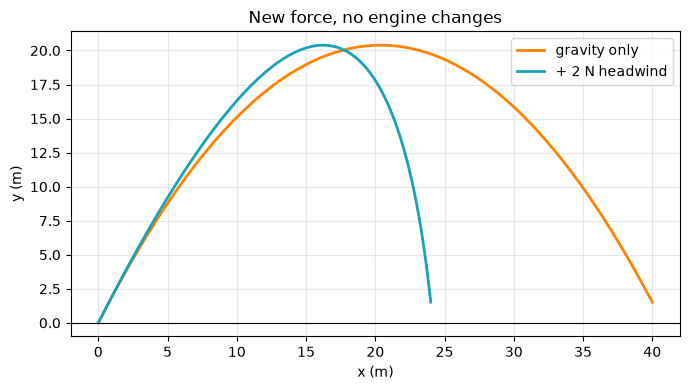

In [16]:
w = World(integrator=VelocityVerlet())
w.add(Body(m=1.0, r=(0, 0), v=(10, 20)))
w.add_force(Gravity(9.81))
w.add_force(Wind((-2.0, 0.0)))
w.record('x', lambda W: W.bodies[0].r[0])
w.record('y', lambda W: W.bodies[0].r[1])
h = w.run(dt=0.001, t_end=4.0)

w2 = World(integrator=VelocityVerlet())
w2.add(Body(m=1.0, r=(0, 0), v=(10, 20)))
w2.add_force(Gravity(9.81))
w2.record('x', lambda W: W.bodies[0].r[0])
w2.record('y', lambda W: W.bodies[0].r[1])
h2 = w2.run(dt=0.001, t_end=4.0)

print("Lines added to Body / Force / Integrator / World:  0")
print(f"x at t = 4 s   no wind: {h2['x'][-1]:8.4f} m")
print(f"               2 N headwind: {h['x'][-1]:8.4f} m")

plt.figure(figsize=(7, 4))
plt.plot(h2['x'], h2['y'], lw=2, color=UT_ORANGE, label='gravity only')
plt.plot(h['x'],  h['y'],  lw=2, color='#17a2b8', label='+ 2 N headwind')
plt.axhline(0, color='k', lw=0.8); plt.xlabel('x (m)'); plt.ylabel('y (m)')
plt.legend(); plt.title('New force, no engine changes'); plt.ylim(bottom=-1)
plt.tight_layout(); plt.show()